# Часть 1

## Этап 1

In [1]:
# Загрузка и первичная проверка данных
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier, CatBoostRegressor
from sklift.metrics import uplift_auc_score, qini_auc_score, uplift_at_k

DATA_PATH = "uplift_fp_data.csv"
df = pd.read_csv(DATA_PATH)
print(f"Размер данных: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
display(df.head())
print("\nТипы данных:")
display(df.dtypes.rename("dtype").to_frame())
print("\nПропуски:")
display(df.isna().sum().rename("число пропусков").to_frame())
print(f"Полных дубликатов: {df.duplicated().sum():,}")
print("\nСводные статистики:")
display(df.describe().T)
assert set(df.columns) == {"recency", "history_segment", "history", "mens", "womens", "zip_code", "newbie", "channel", "treatment", "target"}
assert df[["treatment", "target"]].isin([0, 1]).all().all()


Размер данных: 64,000 строк × 10 столбцов


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,treatment,target
0,10,1,142.44,1,0,1,0,1,1,0
1,6,2,329.08,1,1,2,1,2,0,0
2,7,1,180.65,0,1,1,1,2,1,0
3,9,4,675.83,1,0,2,1,2,0,0
4,2,0,45.34,1,0,0,0,2,1,0



Типы данных:


,dtype
recency,int64
history_segment,int64
history,float64
mens,int64
womens,int64
zip_code,int64
newbie,int64
channel,int64
treatment,int64
target,int64



Пропуски:


,число пропусков
recency,0
history_segment,0
history,0
mens,0
womens,0
zip_code,0
newbie,0
channel,0
treatment,0
target,0


Полных дубликатов: 7,015

Сводные статистики:


,count,mean,std,min,25%,50%,75%,max
recency,64000.0,5.763734,3.507592,1.00,2.00,6.00,9.0000,12.00
history_segment,64000.0,1.481969,1.544514,0.00,0.00,1.00,2.0000,6.00
history,64000.0,242.085656,256.158608,29.99,64.66,158.11,325.6575,3345.93
mens,64000.0,0.551031,0.497393,0.00,0.00,1.00,1.0000,1.00
womens,64000.0,0.549719,0.497526,0.00,0.00,1.00,1.0000,1.00
zip_code,64000.0,0.748469,0.697936,0.00,0.00,1.00,1.0000,2.00
newbie,64000.0,0.502250,0.499999,0.00,0.00,1.00,1.0000,1.00
channel,64000.0,1.319609,0.678254,0.00,1.00,1.00,2.0000,2.00
treatment,64000.0,0.334172,0.471704,0.00,0.00,0.00,1.0000,1.00
target,64000.0,0.146781,0.353890,0.00,0.00,0.00,0.0000,1.00


# Этап 2. Исследовательский анализ

### Исследовательский анализ данных

Распределение treatment:


,число наблюдений
treatment,
Контроль,42613
Воздействие,21387


,число_наблюдений,среднее,стандартное_отклонение,положительные
treatment,,,,
Контроль,42613,0.144463,0.351563,6156
Воздействие,21387,0.151400,0.358447,3238


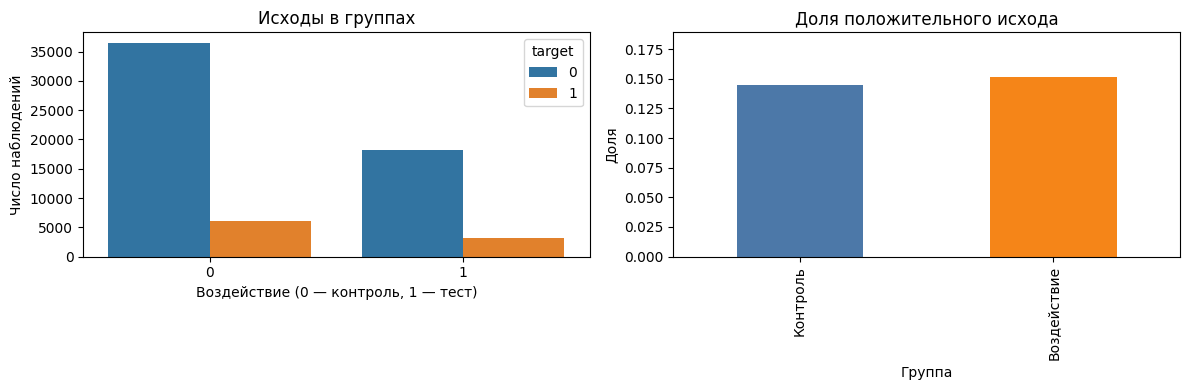

In [2]:
# Распределение воздействия, исхода и сравнение групп
print("Распределение treatment:")
display(df["treatment"].value_counts().sort_index().rename(index={0:"Контроль",1:"Воздействие"}).to_frame("число наблюдений"))
summary = df.groupby("treatment")["target"].agg(число_наблюдений="size", среднее="mean", стандартное_отклонение="std", положительные="sum").rename(index={0:"Контроль",1:"Воздействие"})
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="treatment", hue="target", ax=axes[0])
axes[0].set(title="Исходы в группах", xlabel="Воздействие (0 — контроль, 1 — тест)", ylabel="Число наблюдений")
summary["среднее"].plot(kind="bar", ax=axes[1], color=["#4C78A8", "#F58518"])
axes[1].set(title="Доля положительного исхода", xlabel="Группа", ylabel="Доля", ylim=(0, max(summary["среднее"])*1.25))
plt.tight_layout()


В наборе 64 000 строк, пропусков нет. Полностью совпадают 7 015 строк. Без идентификатора клиента нельзя считать их ошибочными повторами, поэтому они сохранены. Доля положительного отклика составляет 14,45% в группе `treatment=0` и 15,14% в группе `treatment=1`.

В учебной постановке рассматривается рассылка промокодов Яндекс Еды. Построчное сопоставление предоставленного Практикумом CSV с [открытым набором Hillstrom](https://raw.githubusercontent.com/W-Tran/uplift-modelling/master/data/hillstrom/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv) подтвердило соответствие всех 64 000 записей и признаков. В этих данных `target` соответствует посещению сайта (`visit`), а не покупке или использованию промокода. Группа `treatment=1` соответствует Womens E-Mail, группа `treatment=0` объединяет Mens E-Mail и No E-Mail. Состав групп и целевой столбец сохранены. Поэтому метрики сравнивают отклик в заданных группах, а не измеряют отдельно эффект рассылки относительно её отсутствия.

### Проверка статистической значимости

Сравним доли положительного отклика в двух группах и проверим, насколько велико наблюдаемое различие.

Проверена нулевая гипотеза о равенстве долей положительного отклика в двух независимых группах против двусторонней альтернативы. Для больших выборок применён z-тест долей. Доля отклика в группе `treatment=1` выше на 0,6937 процентного пункта; получены z = −2,339 и p-value = 0,01932. При уровне значимости 5% нулевая гипотеза отвергается. Это различие наблюдаемых долей не доказывает индивидуальный эффект воздействия. Группа `treatment=0` объединяет Mens E-Mail и No E-Mail.

In [3]:
# Сравнение долей положительного исхода между независимыми группами
from statsmodels.stats.proportion import proportions_ztest
counts = df.groupby("treatment")["target"].agg(["sum", "count"]).sort_index()
stat_z, p_value = proportions_ztest(counts["sum"].to_numpy(), counts["count"].to_numpy())
rate_control = counts.loc[0,"sum"] / counts.loc[0,"count"]
rate_treat = counts.loc[1,"sum"] / counts.loc[1,"count"]
print(f"Контроль: {rate_control:.4%}; тест: {rate_treat:.4%}")
print(f"Разность долей (тест − контроль): {rate_treat-rate_control:.4%}")
print(f"z={stat_z:.3f}, p-value={p_value:.4g}")


Контроль: 14.4463%; тест: 15.1400%
Разность долей (тест − контроль): 0.6937%
z=-2.339, p-value=0.01932


### Корреляции признаков

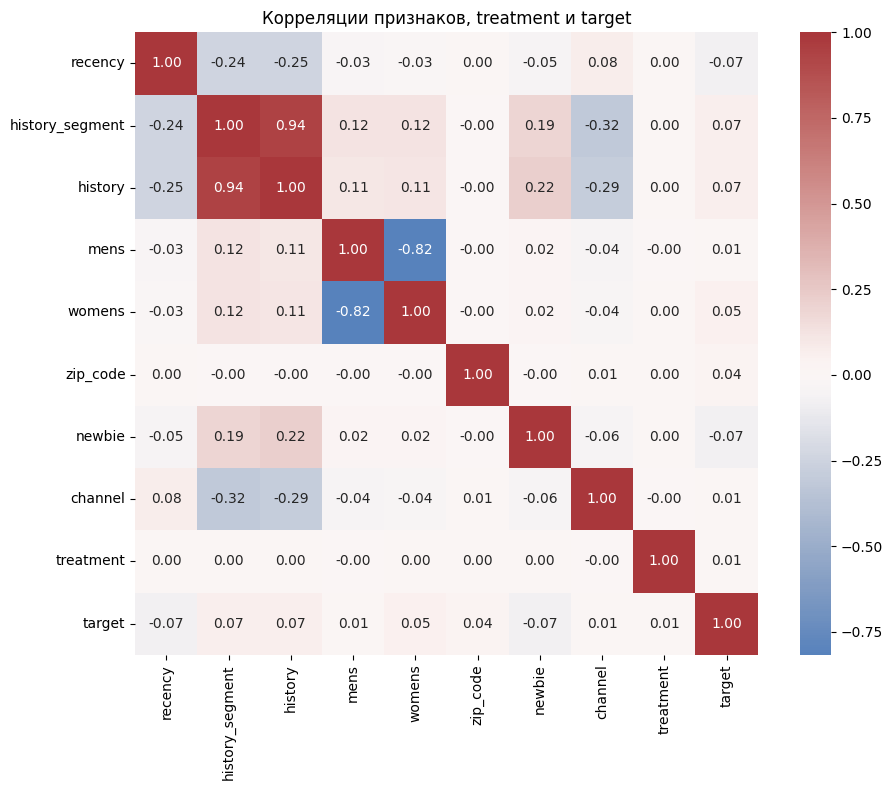

In [4]:
# Корреляционная матрица числовых признаков и целевых столбцов
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Корреляции признаков, treatment и target")
plt.tight_layout()


В матрице заметна сильная положительная связь `history_segment` и `history` (около 0,94), а также сильная отрицательная связь `mens` и `womens` (около −0,82). Связь отдельных признаков с `target` слабая: абсолютные коэффициенты в основном не превышают примерно 0,07. Связь `history_segment` с `history` может объясняться тем, что категория учитывает историю клиента, но это предположение. Корреляция показывает линейную связь, а не причину и следствие. Для `history_segment`, `zip_code` и `channel`, заданных числовыми кодами, коэффициент Пирсона нужно трактовать осторожно.

В целом пропусков нет, а положительный отклик наблюдается примерно у 14–15% клиентов. В группе воздействия его доля немного выше, чем в контрольной; различие статистически значимо, но это само по себе не доказывает причинный эффект. Некоторые признаки сильно связаны друг с другом, тогда как их линейные связи с `target` невелики. Для оценки различий отклика между группами далее используются uplift-модели.

## Этап 3

Сравниваются S-, T- и X-Learner на основе CatBoost. S-Learner использует один классификатор с признаком воздействия, T-Learner — отдельные модели для двух групп, а X-Learner дополнительно обучает модели эффекта. Исходной моделью выбрана S-Learner, поскольку она требует одного классификатора. Её качество сравнивается с двумя другими подходами. Прогнозируемый uplift относится к различию отклика между Womens E-Mail (`treatment=1`) и объединённой группой Mens E-Mail и No E-Mail (`treatment=0`).

### Обучение uplift-моделей

Для сравнения моделей используются одинаковые обучающая и тестовая выборки. При разбиении задан `random_state=42`, в моделях CatBoost — случайное зерно 42. Прогноз uplift для расчёта метрик представлен одномерным массивом.

### Разбиение выборки на тренировочную и тестовую

In [5]:
# Разделение 80/20 со стратификацией по комбинации treatment и target
feature_cols = [c for c in df.columns if c not in ("treatment", "target")]
X = df[feature_cols].copy()
treatment = df["treatment"].astype(int)
y = df["target"].astype(int)
strata = treatment.astype(str) + "_" + y.astype(str)
X_train, X_test, t_train, t_test, y_train, y_test = train_test_split(
    X, treatment, y, test_size=0.2, random_state=42, stratify=strata
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train treatment/target strata:")
display(pd.crosstab(t_train, y_train, normalize="all").round(4))

assert len(X_train) == 51200 and len(X_test) == 12800
assert set(X.columns).isdisjoint({"treatment", "target"})


Train: (51200, 8) Test: (12800, 8)
Train treatment/target strata:


target,0,1
treatment,,
0,0.5696,0.0962
1,0.2836,0.0506


### Обучение исходной модели

In [6]:
# Единые параметры CatBoost для сопоставимого сравнения
CAT_PARAMS = dict(iterations=350, depth=6, learning_rate=0.05, l2_leaf_reg=5,
                  loss_function="Logloss", random_seed=42, verbose=False,
                  allow_writing_files=False, thread_count=4, auto_class_weights="Balanced")

def new_classifier():
    return CatBoostClassifier(**CAT_PARAMS)

# S-Learner: одна модель включает индикатор воздействия; прогнозируем оба потенциальных исхода.
s_model = new_classifier()
s_model.fit(X_train.assign(treatment=t_train.to_numpy()), y_train)
s_uplift = (s_model.predict_proba(X_test.assign(treatment=1))[:, 1]
            - s_model.predict_proba(X_test.assign(treatment=0))[:, 1])


### Оценка исходной модели на тестовой выборке

In [7]:
# Оценка на отложенной тестовой выборке
def uplift_metrics(y_true, uplift, treatment_true):
    return {
        "Uplift AUC": uplift_auc_score(y_true, uplift, treatment_true),
        "Qini AUC": qini_auc_score(y_true, uplift, treatment_true),
        "Uplift@30%": uplift_at_k(y_true, uplift, treatment_true, strategy="overall", k=0.3),
    }
results = {"S-Learner": uplift_metrics(y_test, s_uplift, t_test)}
# Uplift@30%: верхние 30% тестовой выборки по прогнозу, затем разность долей отклика.
segment_size = int(len(y_test) * 0.30)
top_idx = np.argsort(np.asarray(s_uplift), kind="mergesort")[::-1][:segment_size]
top_t = np.asarray(t_test)[top_idx]
top_y = np.asarray(y_test)[top_idx]
print(f"Размер top-сегмента: {segment_size:,} из {len(y_test):,}")
print(f"Контроль в сегменте: {(top_t == 0).sum():,}; тест: {(top_t == 1).sum():,}")
print(f"Ручная проверка uplift@30%: {top_y[top_t == 1].mean() - top_y[top_t == 0].mean():.6f}")
print(results["S-Learner"])


Размер top-сегмента: 3,840 из 12,800
Контроль в сегменте: 2,534; тест: 1,306
Ручная проверка uplift@30%: 0.036652
{'Uplift AUC': 0.02249327623966757, 'Qini AUC': 0.05038227507670589, 'Uplift@30%': 0.036651916780181565}


### Обучение T- и X-Learner

### T-Learner

In [8]:
# T-Learner: отдельный классификатор исхода для каждой группы
control_model = new_classifier().fit(X_train.loc[t_train == 0], y_train.loc[t_train == 0])
treatment_model = new_classifier().fit(X_train.loc[t_train == 1], y_train.loc[t_train == 1])
t_uplift = (treatment_model.predict_proba(X_test)[:, 1]
            - control_model.predict_proba(X_test)[:, 1])


### Метрики T-Learner

In [9]:
results["T-Learner"] = uplift_metrics(y_test, t_uplift, t_test)
print(results["T-Learner"])


{'Uplift AUC': 0.017762671409707942, 'Qini AUC': 0.039542589938533275, 'Uplift@30%': 0.03591860139487124}


### X-Learner

In [10]:
# X-Learner: модели исхода, псевдоэффекты в обеих группах и модели эффектов
# Используем вероятности положительного исхода как условные ожидания бинарного target.
mu0 = new_classifier().fit(X_train.loc[t_train == 0], y_train.loc[t_train == 0])
mu1 = new_classifier().fit(X_train.loc[t_train == 1], y_train.loc[t_train == 1])
X0, X1 = X_train.loc[t_train == 0], X_train.loc[t_train == 1]
y0, y1 = y_train.loc[t_train == 0], y_train.loc[t_train == 1]
# D0 = mu1(X0) - Y0; D1 = Y1 - mu0(X1)
d0 = mu1.predict_proba(X0)[:, 1] - y0.to_numpy()
d1 = y1.to_numpy() - mu0.predict_proba(X1)[:, 1]
effect0 = CatBoostRegressor(iterations=350, depth=6, learning_rate=0.05, l2_leaf_reg=5,
    loss_function="RMSE", random_seed=42, verbose=False, allow_writing_files=False, thread_count=4).fit(X0, d0)
effect1 = CatBoostRegressor(iterations=350, depth=6, learning_rate=0.05, l2_leaf_reg=5,
    loss_function="RMSE", random_seed=42, verbose=False, allow_writing_files=False, thread_count=4).fit(X1, d1)
# В этой реализации две оценки эффекта усредняются с равными весами.
x_uplift = 0.5 * (effect0.predict(X_test) + effect1.predict(X_test))


### Метрики X-Learner

,Uplift AUC,Qini AUC,Uplift@30%
Модель,,,
S-Learner,0.022493,0.050382,0.036652
X-Learner,0.020918,0.046662,0.034681
T-Learner,0.017763,0.039543,0.035919


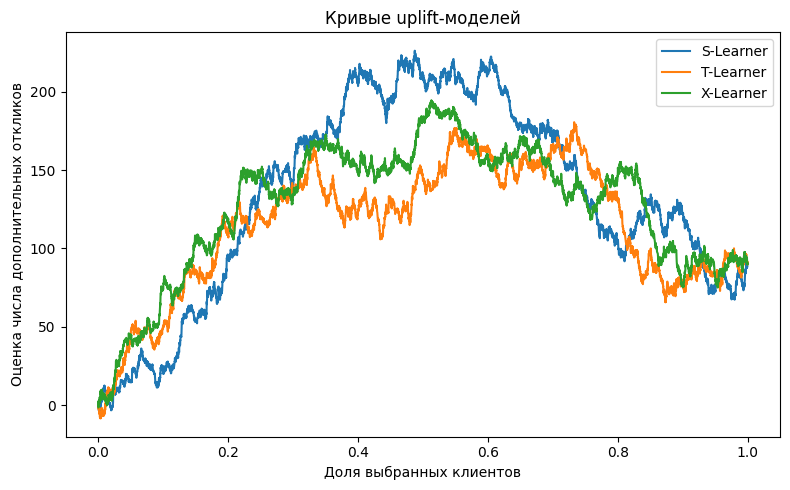

,Контрольная модель эффекта,Тестовая модель эффекта,Средняя важность
recency,18.986362,21.123446,20.054904
history,18.648878,19.677687,19.163283
newbie,9.257188,15.778983,12.518085
womens,21.553793,3.344457,12.449125
channel,10.901257,11.295218,11.098238
zip_code,10.158118,11.761949,10.960033
mens,4.596168,11.034301,7.815235
history_segment,5.898236,5.983959,5.941097


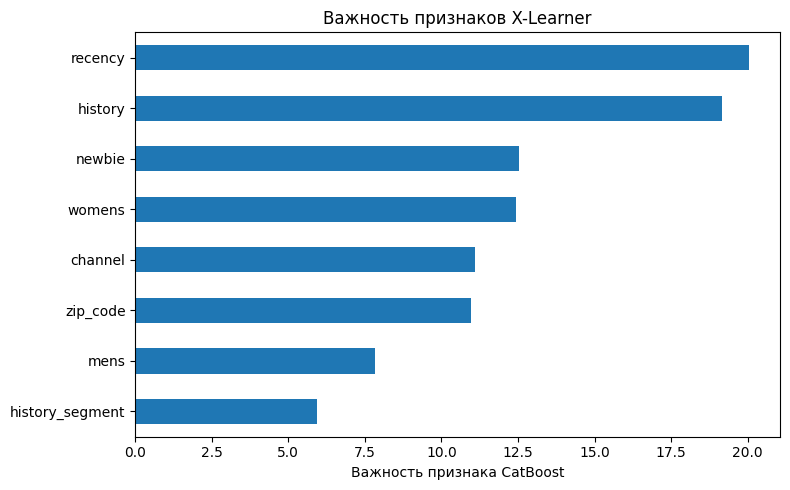

Наибольшую среднюю важность для оценки эффекта имеют: recency, history, newbie, womens, channel


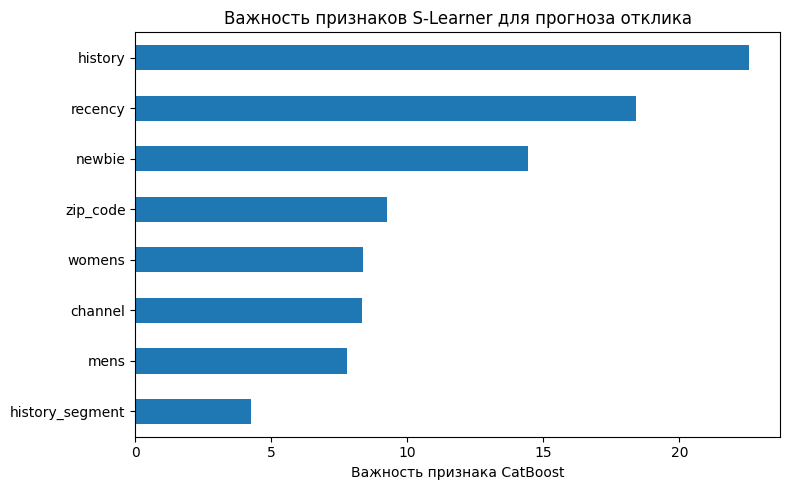

Эта важность описывает прогноз отклика и сама по себе не показывает причинное влияние признаков на эффект воздействия.


In [11]:
results["X-Learner"] = uplift_metrics(y_test, x_uplift, t_test)
results_df = pd.DataFrame(results).T
results_df.index.name = "Модель"
display(results_df.sort_values("Uplift AUC", ascending=False))

# Кривые показывают накопленное число дополнительных откликов при ранжировании клиентов.
from sklift.metrics import uplift_curve
fig, ax = plt.subplots(figsize=(8, 5))
for name, pred in {"S-Learner": s_uplift, "T-Learner": t_uplift, "X-Learner": x_uplift}.items():
    x_curve, y_curve = uplift_curve(y_test, pred, t_test)
    ax.plot(x_curve / len(y_test), y_curve, label=name)
ax.set_xlabel("Доля выбранных клиентов")
ax.set_ylabel("Оценка числа дополнительных откликов")
ax.set_title("Кривые uplift-моделей")
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

# Важность признаков X-Learner берётся из моделей псевдоэффекта.
importance = pd.DataFrame({"Контрольная модель эффекта": effect0.feature_importances_,
                           "Тестовая модель эффекта": effect1.feature_importances_}, index=feature_cols)
importance["Средняя важность"] = importance.mean(axis=1)
importance = importance.sort_values("Средняя важность", ascending=False)
display(importance.head(10))
fig_x, ax_x = plt.subplots(figsize=(8, 5))
importance["Средняя важность"].head(10).sort_values().plot(kind="barh", ax=ax_x)
ax_x.set_xlabel("Важность признака CatBoost")
ax_x.set_title("Важность признаков X-Learner")
fig_x.tight_layout()
plt.show()
plt.close(fig_x)
print("Наибольшую среднюю важность для оценки эффекта имеют:", ", ".join(importance.head(5).index))


# Важность S-Learner для прогноза отклика
s_importance = pd.Series(s_model.feature_importances_, index=feature_cols + ["treatment"]).drop("treatment").sort_values(ascending=False)
fig_s, ax_s = plt.subplots(figsize=(8, 5))
s_importance.head(10).sort_values().plot(kind="barh", ax=ax_s)
ax_s.set_xlabel("Важность признака CatBoost")
ax_s.set_title("Важность признаков S-Learner для прогноза отклика")
fig_s.tight_layout()
plt.show()
plt.close(fig_s)
print("Эта важность описывает прогноз отклика и сама по себе не показывает причинное влияние признаков на эффект воздействия.")


На test наибольший Uplift@30% у S-Learner (0,0367); у T-Learner — 0,0359, у X-Learner — 0,0347. Различия небольшие, их статистическая значимость отдельно не проверялась. Возможно, S-Learner помогло обучение одного классификатора на всей выборке, тогда как T-Learner обучает две модели на меньших группах. В этом сравнении S-Learner выбрана исходной моделью для дальнейших экспериментов.

Метрики относятся к сравнению Womens E-Mail с объединённой группой Mens E-Mail и No E-Mail. Их нельзя трактовать как чистый эффект рассылки относительно её отсутствия. `target` соответствует посещению сайта; покупка и использование промокода не оцениваются.

# Часть 2

## Этап 1 | Улучшение выбранной модели

In [12]:
# Внутренняя валидация: исходный test остаётся отложенным.
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from sklift.metrics import uplift_at_k, uplift_auc_score, qini_auc_score

validation_strata = t_train.astype(str) + "_" + y_train.astype(str)
X_internal, X_valid, t_internal, t_valid, y_internal, y_valid = train_test_split(
    X_train, t_train, y_train, test_size=0.2, random_state=42,
    stratify=validation_strata
)
assert (len(X_internal), len(X_valid)) == (40960, 10240)
assert X_internal.index.intersection(X_valid.index).empty
assert X_internal.columns.equals(X_valid.columns)
assert "target" not in X_internal.columns and "treatment" not in X_internal.columns
strata_share = pd.DataFrame({
    "internal train": pd.crosstab(t_internal, y_internal, normalize="all").stack(),
    "validation": pd.crosstab(t_valid, y_valid, normalize="all").stack(),
})
display(strata_share)
assert (strata_share.iloc[:, 0] - strata_share.iloc[:, 1]).abs().max() < 0.001
print("Размеры:", len(X_internal), len(X_valid))

def validation_metrics(y_true, uplift, treatment_true):
    return {
        "Uplift@30%": uplift_at_k(y_true, uplift, treatment_true, strategy="overall", k=0.3),
        "Uplift AUC": uplift_auc_score(y_true, uplift, treatment_true),
        "Qini AUC": qini_auc_score(y_true, uplift, treatment_true),
    }

BASE_PARAMS = dict(iterations=350, depth=6, learning_rate=0.05, l2_leaf_reg=5,
                   loss_function="Logloss", random_seed=42, verbose=False,
                   allow_writing_files=False, thread_count=4, auto_class_weights="Balanced")

def fit_s_learner(params, X_fit, t_fit, y_fit, X_eval):
    fitted = CatBoostClassifier(**params)
    fitted.fit(X_fit.assign(treatment=t_fit.to_numpy()), y_fit)
    uplift = (fitted.predict_proba(X_eval.assign(treatment=1))[:, 1]
              - fitted.predict_proba(X_eval.assign(treatment=0))[:, 1])
    return fitted, uplift

baseline_model, baseline_valid_uplift = fit_s_learner(
    BASE_PARAMS, X_internal, t_internal, y_internal, X_valid
)
baseline_metrics = validation_metrics(y_valid, baseline_valid_uplift, t_valid)
print("Исходная S-Learner на validation:", baseline_metrics)

internal train  validation
treatment target                            
0         0             0.569653    0.569629
          1             0.096191    0.096191
1         0             0.283569    0.283594
          1             0.050586    0.050586

Размеры: 40960 10240


Исходная S-Learner на validation: {'Uplift@30%': 0.04232312808164203, 'Uplift AUC': 0.02813985289201948, 'Qini AUC': 0.061476318224403574}


Для подбора параметров исходный `train` разделён на внутреннюю обучающую и валидационную выборки. Отложенный `test` при выборе модели не используется. Преобразования признаков ниже рассчитываются отдельно для каждой строки без обращения к целевому столбцу или наблюдаемому воздействию. Совпадающие строки могут попасть в разные выборки: без идентификатора клиента невозможно отличить повторную запись от разных клиентов с одинаковыми признаками, поэтому исходное разбиение сохранено.

In [13]:
def add_simple_features(frame):
    result = frame.copy()
    # История взаимодействий в пересчёте на время с последнего контакта.
    result["history_per_recency"] = result["history"] / (result["recency"] + 1)
    # Совместный индикатор интереса к двум категориям товаров.
    result["both_categories"] = result["mens"] * result["womens"]
    return result

X_internal_extra = add_simple_features(X_internal)
X_valid_extra = add_simple_features(X_valid)
assert X_internal_extra.columns.equals(X_valid_extra.columns)
assert "target" not in X_internal_extra.columns

### Подбор гиперпараметров и выбор модели

Для S-Learner с CatBoost проведено 40 успешных испытаний Optuna (TPESampler, seed 42). Подбирались число деревьев, глубина, скорость обучения и параметры регуляризации. После этого проверены два простых признака и S-Learner с LightGBM (15 успешных испытаний). Все варианты обучались на internal train и сравнивались на одной validation; тестовая выборка в подборе не участвовала.

| Модель | Uplift@30% | Uplift AUC | Qini AUC |
|---|---:|---:|---:|
| Исходная S-Learner (CatBoost) | 0,042323 | 0,028140 | 0,061476 |
| CatBoost Optuna №1 | 0,049163 | 0,024786 | 0,054521 |
| CatBoost Optuna №2 | 0,045544 | 0,026766 | 0,058475 |
| CatBoost Optuna №3 | 0,045217 | 0,027281 | 0,059388 |
| CatBoost Optuna №1 с новыми признаками | 0,029203 | 0,023743 | 0,051691 |
| LightGBM Optuna №1 | 0,055869 | 0,031020 | 0,068089 |

На другом фиксированном разбиении исходного train исходная S-Learner получила Uplift@30% 0,030107, CatBoost Optuna №1 — 0,029586, CatBoost Optuna №2 — 0,026724, вариант с новыми признаками — 0,025695, LightGBM — 0,026412. Таким образом, выигрыш новых моделей на первой validation не подтвердился. У лучшего CatBoost также снизились Uplift AUC и Qini AUC. На втором разбиении ни один из проверенных вариантов не превзошёл исходную S-Learner, поэтому оставили её. Её параметры зафиксированы в BASE_PARAMS; финальная модель обучена на всех 51 200 наблюдениях исходного train. Итоговая оценка на отложенном test приведена в следующем этапе.

In [14]:
import optuna
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = dict(BASE_PARAMS)
    params.update(
        iterations=trial.suggest_int("iterations", 180, 600, step=60),
        depth=trial.suggest_int("depth", 3, 7),
        learning_rate=trial.suggest_float("learning_rate", 0.025, 0.15, log=True),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 2.0, 20.0, log=True),
        random_strength=trial.suggest_float("random_strength", 0.0, 2.0),
    )
    _, uplift = fit_s_learner(params, X_internal, t_internal, y_internal, X_valid)
    metrics = validation_metrics(y_valid, uplift, t_valid)
    trial.set_user_attr("Uplift AUC", metrics["Uplift AUC"])
    trial.set_user_attr("Qini AUC", metrics["Qini AUC"])
    return metrics["Uplift@30%"]

study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=42))
study.optimize(objective, n_trials=40, n_jobs=1, catch=(Exception,))
complete_trials = [tr for tr in study.trials if tr.state == optuna.trial.TrialState.COMPLETE]
assert complete_trials, "Нет успешных испытаний Optuna"
print("Успешных trials:", len(complete_trials))
print("Лучшие параметры:", study.best_params)

top_trials = sorted(complete_trials, key=lambda tr: tr.value, reverse=True)[:3]
candidate_rows = {"Исходная S-Learner": baseline_metrics}
candidate_params = {}
for rank, tr in enumerate(top_trials, 1):
    label = f"CatBoost Optuna #{rank}"
    params = dict(BASE_PARAMS, **tr.params)
    _, prediction = fit_s_learner(params, X_internal, t_internal, y_internal, X_valid)
    candidate_rows[label] = validation_metrics(y_valid, prediction, t_valid)
    candidate_params[label] = params

# Ограниченный эксперимент с двумя осмысленными признаками.
feature_label = "CatBoost Optuna #1 + признаки"
feature_params = candidate_params["CatBoost Optuna #1"]
_, feature_prediction = fit_s_learner(
    feature_params, X_internal_extra, t_internal, y_internal, X_valid_extra
)
candidate_rows[feature_label] = validation_metrics(y_valid, feature_prediction, t_valid)
candidate_params[feature_label] = feature_params
comparison = pd.DataFrame(candidate_rows).T
display(comparison.round(6))

# Небольшой альтернативный поиск S-Learner на LightGBM.
from lightgbm import LGBMClassifier
def lightgbm_uplift(params, X_fit, t_fit, y_fit, X_eval):
    model = LGBMClassifier(**params)
    model.fit(X_fit.assign(treatment=t_fit.to_numpy()), y_fit)
    uplift = (model.predict_proba(X_eval.assign(treatment=1))[:, 1]
              - model.predict_proba(X_eval.assign(treatment=0))[:, 1])
    return model, uplift

def lightgbm_objective(trial):
    params = dict(n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
                  max_depth=trial.suggest_int("max_depth", 2, 5),
                  num_leaves=trial.suggest_int("num_leaves", 4, 24),
                  learning_rate=trial.suggest_float("learning_rate", 0.015, 0.1, log=True),
                  min_child_samples=trial.suggest_int("min_child_samples", 80, 400),
                  reg_lambda=trial.suggest_float("reg_lambda", 1.0, 20.0, log=True),
                  random_state=42, n_jobs=4, verbosity=-1, class_weight="balanced",
                  deterministic=True, force_col_wise=True)
    _, pred = lightgbm_uplift(params, X_internal, t_internal, y_internal, X_valid)
    metrics = validation_metrics(y_valid, pred, t_valid)
    trial.set_user_attr("Uplift AUC", metrics["Uplift AUC"])
    trial.set_user_attr("Qini AUC", metrics["Qini AUC"])
    return metrics["Uplift@30%"]

lightgbm_study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=42))
lightgbm_study.optimize(lightgbm_objective, n_trials=15, n_jobs=1, catch=(Exception,))
lightgbm_complete = [tr for tr in lightgbm_study.trials if tr.state == optuna.trial.TrialState.COMPLETE]
print("Успешных LightGBM trials:", len(lightgbm_complete))
if lightgbm_complete:
    lightgbm_params = dict(lightgbm_study.best_params, random_state=42, n_jobs=4,
                           verbosity=-1, class_weight="balanced",
                           deterministic=True, force_col_wise=True)
    _, lightgbm_pred = lightgbm_uplift(lightgbm_params, X_internal, t_internal, y_internal, X_valid)
    candidate_rows["LightGBM Optuna #1"] = validation_metrics(y_valid, lightgbm_pred, t_valid)
    comparison = pd.DataFrame(candidate_rows).T
    display(comparison.round(6))

# Второе фиксированное разбиение служит проверкой устойчивости, не финальным тестом.
X_check_train, X_check_valid, t_check_train, t_check_valid, y_check_train, y_check_valid = train_test_split(
    X_train, t_train, y_train, test_size=0.2, random_state=21,
    stratify=validation_strata
)
check_rows = {}
for label in ["Исходная S-Learner", "CatBoost Optuna #1", "CatBoost Optuna #2", feature_label] + (["LightGBM Optuna #1"] if lightgbm_complete else []):
    extra = label == feature_label
    X_fit = add_simple_features(X_check_train) if extra else X_check_train
    X_eval = add_simple_features(X_check_valid) if extra else X_check_valid
    params = BASE_PARAMS if label == "Исходная S-Learner" else (lightgbm_params if label == "LightGBM Optuna #1" else candidate_params[label])
    _, pred = (lightgbm_uplift(lightgbm_params, X_fit, t_check_train, y_check_train, X_eval)
               if label == "LightGBM Optuna #1" else
               fit_s_learner(params, X_fit, t_check_train, y_check_train, X_eval))
    check_rows[label] = validation_metrics(y_check_valid, pred, t_check_valid)
stability = pd.DataFrame(check_rows).T
display(stability.round(6))

# Выбор по основной метрике с учётом второй проверки и простоты инференса.
eligible = [label for label in check_rows if label in comparison.index]
mean_scores = {label: (comparison.loc[label, "Uplift@30%"] + stability.loc[label, "Uplift@30%"])/2
               for label in eligible}
# Требуем улучшение на обеих проверках, иначе сохраняем исходную модель.
robust = [label for label in eligible if label != "Исходная S-Learner"
          and comparison.loc[label, "Uplift@30%"] > comparison.loc["Исходная S-Learner", "Uplift@30%"]
          and stability.loc[label, "Uplift@30%"] > stability.loc["Исходная S-Learner", "Uplift@30%"]]
selected_name = max(robust, key=mean_scores.get) if robust else "Исходная S-Learner"
selected_params = BASE_PARAMS if selected_name == "Исходная S-Learner" else (lightgbm_params if selected_name == "LightGBM Optuna #1" else candidate_params[selected_name])
selected_extra = selected_name == feature_label
final_feature_cols = list(add_simple_features(X_train).columns) if selected_extra else list(X_train.columns)
final_train_features = add_simple_features(X_train) if selected_extra else X_train.copy()
final_model = (LGBMClassifier(**selected_params) if selected_name == "LightGBM Optuna #1"
               else CatBoostClassifier(**selected_params))
final_model.fit(final_train_features.assign(treatment=t_train.to_numpy()), y_train)
assert len(final_train_features) == 51200
print("Выбрана:", selected_name)
print("Признаки финальной модели:", final_feature_cols)
print("Финальная модель обучена на", len(final_train_features), "наблюдениях")

Успешных trials: 40
Лучшие параметры: {'iterations': 240, 'depth': 7, 'learning_rate': 0.04934211028012115, 'l2_leaf_reg': 3.9361244751630378, 'random_strength': 0.21279434187498628}


,Uplift@30%,Uplift AUC,Qini AUC
Исходная S-Learner,0.042323,0.028140,0.061476
CatBoost Optuna #1,0.049163,0.024786,0.054521
CatBoost Optuna #2,0.045544,0.026766,0.058475
CatBoost Optuna #3,0.045217,0.027281,0.059388
CatBoost Optuna #1 + признаки,0.029203,0.023743,0.051691


Успешных LightGBM trials: 15


,Uplift@30%,Uplift AUC,Qini AUC
Исходная S-Learner,0.042323,0.028140,0.061476
CatBoost Optuna #1,0.049163,0.024786,0.054521
CatBoost Optuna #2,0.045544,0.026766,0.058475
CatBoost Optuna #3,0.045217,0.027281,0.059388
CatBoost Optuna #1 + признаки,0.029203,0.023743,0.051691
LightGBM Optuna #1,0.055869,0.031020,0.068089


,Uplift@30%,Uplift AUC,Qini AUC
Исходная S-Learner,0.030107,0.015942,0.034809
CatBoost Optuna #1,0.029586,0.014865,0.032752
CatBoost Optuna #2,0.026724,0.014935,0.032572
CatBoost Optuna #1 + признаки,0.025695,0.015155,0.033423
LightGBM Optuna #1,0.026412,0.015314,0.033215


Выбрана: Исходная S-Learner
Признаки финальной модели: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel']
Финальная модель обучена на 51200 наблюдениях


## Этап 2 | Оценка и визуализация результатов

### Итоговая оценка и графики

In [15]:
# Итоговая оценка выбранной модели на отложенной тестовой выборке
from utils import custom_uplift_by_percentile
from sklift.metrics import uplift_curve, qini_curve, uplift_by_percentile

final_test_uplift = (
    final_model.predict_proba(X_test[final_feature_cols].assign(treatment=1))[:, 1]
    - final_model.predict_proba(X_test[final_feature_cols].assign(treatment=0))[:, 1]
)
final_test_metrics = validation_metrics(y_test, final_test_uplift, t_test)
historical_s_metrics = results["S-Learner"]
final_comparison = pd.DataFrame(
    {"S-Learner, первая часть": historical_s_metrics,
     "Финальная S-Learner": final_test_metrics}
).T[["Uplift@30%", "Uplift AUC", "Qini AUC"]]
display(final_comparison.round(6))
np.testing.assert_allclose(
    final_comparison.iloc[0].to_numpy(dtype=float),
    final_comparison.iloc[1].to_numpy(dtype=float),
    rtol=0, atol=1e-12
)
print("Итоговая модель воспроизводит исторические метрики S-Learner.")

,Uplift@30%,Uplift AUC,Qini AUC
"S-Learner, первая часть",0.036652,0.022493,0.050382
Финальная S-Learner,0.036652,0.022493,0.050382


Итоговая модель воспроизводит исторические метрики S-Learner.


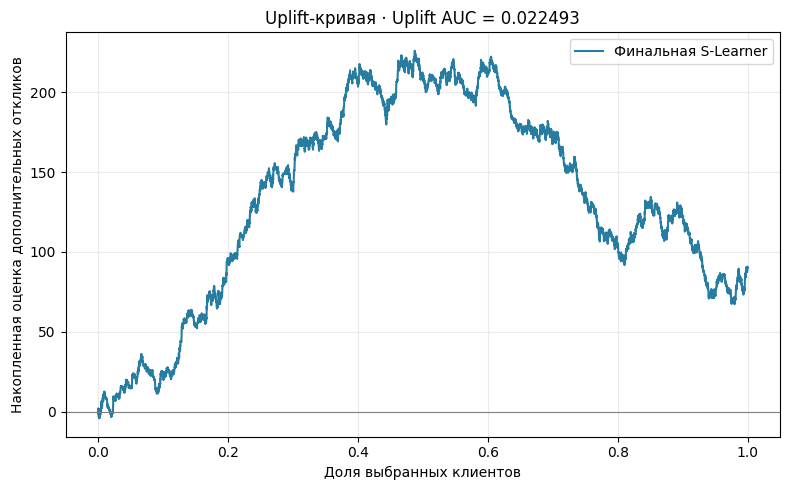

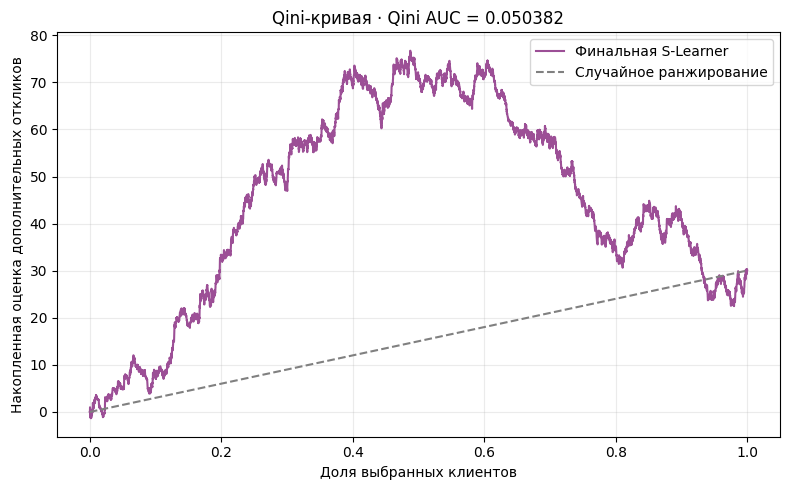

In [16]:
# Разные определения кривых представлены на отдельных рисунках.
uplift_x, uplift_y = uplift_curve(y_test, final_test_uplift, t_test)
fig_u, ax_u = plt.subplots(figsize=(8, 5))
ax_u.plot(uplift_x / len(y_test), uplift_y, color="#277DA1", label="Финальная S-Learner")
ax_u.axhline(0, color="gray", linewidth=0.8)
ax_u.set(xlabel="Доля выбранных клиентов", ylabel="Накопленная оценка дополнительных откликов",
         title=f"Uplift-кривая · Uplift AUC = {final_test_metrics['Uplift AUC']:.6f}")
ax_u.legend()
ax_u.grid(alpha=0.25)
fig_u.tight_layout()
plt.show()
plt.close(fig_u)

qini_x, qini_y = qini_curve(y_test, final_test_uplift, t_test)
fig_q, ax_q = plt.subplots(figsize=(8, 5))
ax_q.plot(qini_x / len(y_test), qini_y, color="#9C4F96", label="Финальная S-Learner")
ax_q.plot([0, 1], [0, qini_y[-1]], linestyle="--", color="gray", label="Случайное ранжирование")
ax_q.set(xlabel="Доля выбранных клиентов", ylabel="Накопленная оценка дополнительных откликов",
         title=f"Qini-кривая · Qini AUC = {final_test_metrics['Qini AUC']:.6f}")
ax_q.legend()
ax_q.grid(alpha=0.25)
fig_q.tight_layout()
plt.show()
plt.close(fig_q)

,n_treatment,n_control,uplift
percentile,,,
10,447,833,0.0164
20,444,836,0.0586
30,415,865,0.0371
40,423,857,0.0516
50,444,836,0.0024
60,413,867,0.0008
70,405,875,-0.0380
80,426,854,-0.0513
90,436,844,0.0148


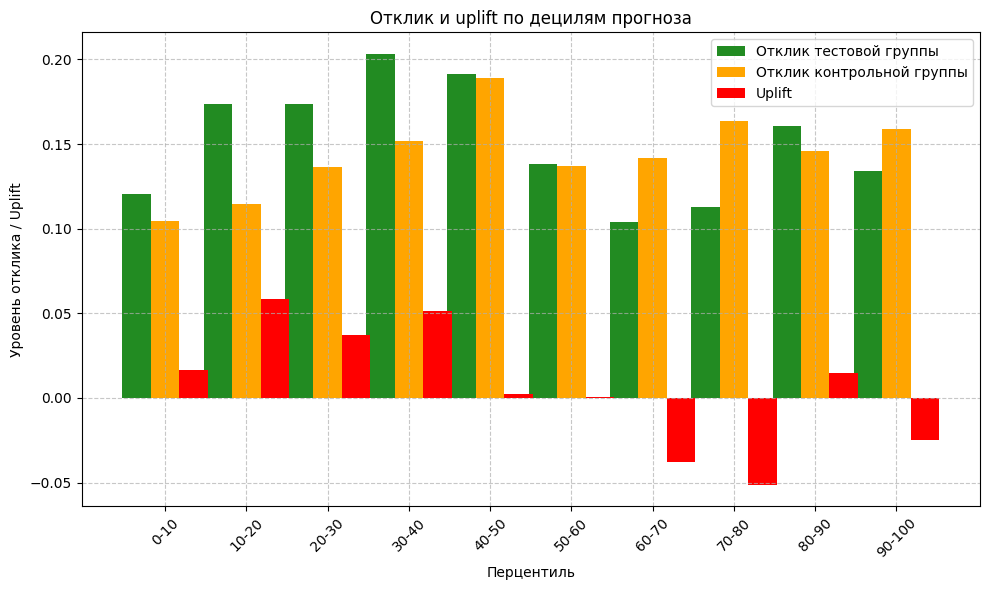

In [17]:
# Uplift по десяти группам, упорядоченным по предсказанному эффекту.
percentile_table = uplift_by_percentile(
    y_test, final_test_uplift, t_test, strategy="overall",
    bins=10, std=True, total=False, string_percentiles=False
)
display(percentile_table[["n_treatment", "n_control", "uplift"]].round(4))
assert len(percentile_table) == 10
assert int(percentile_table["n_treatment"].sum() + percentile_table["n_control"].sum()) == len(X_test)
fig_p = custom_uplift_by_percentile(
    y_test, final_test_uplift, t_test, kind="bar", bins=10,
    title="Отклик и uplift по децилям прогноза"
)
plt.show()
plt.close(fig_p)

Финальная S-Learner на test получила Uplift@30% 0,036652, Uplift AUC 0,022493 и Qini AUC 0,050382. Это показатели исходной модели: после проверки устойчивости её параметры не менялись. По критериям задания Uplift@30% достиг удовлетворительного уровня, но ниже порога «хорошо» (0,045).

Uplift-кривая растёт быстрее в верхней части списка, а Qini-кривая там проходит выше линии случайного ранжирования. Это указывает на полезное ранжирование, хотя кривые заметно колеблются. В первых четырёх децилях наблюдаемый uplift положителен; максимальное значение — около 0,059 во втором дециле. В седьмом и восьмом децилях он отрицателен. Для отбора клиентов поэтому разумнее рассматривать верхние группы прогноза, предварительно проверив устойчивость такого решения.

На первой validation некоторые варианты CatBoost и LightGBM показали более высокий Uplift@30%, но на другом разбиении преимущество исчезло. Для более надёжной оценки нужны несколько валидационных разбиений и доверительные интервалы метрик. Более информативные признаки и другие подходы, например R-Learner и DR-Learner, можно проверить в дальнейших экспериментах без обещания прироста качества. Test ранее использовался при сравнении архитектур в первой части, поэтому итоговая оценка не полностью независима от выбора S-Learner. Результаты не доказывают индивидуальный причинный эффект и не показывают чистый эффект рассылки относительно её отсутствия.

## Этап 3 | Инференс модели

In [18]:
# Инференс финальной S-Learner
class UpliftModelInference:
    def __init__(self, model, feature_names, logger=None):
        self.model = model
        self.feature_names = list(feature_names)
        self.logger = logger

    def _transform_data(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Ожидается pandas.DataFrame")
        missing = [name for name in self.feature_names if name not in X.columns]
        if missing:
            raise ValueError(f"Отсутствуют признаки: {missing}")
        features = X.loc[:, self.feature_names].copy()
        if features.isna().any().any():
            raise ValueError("Входные данные содержат пропуски")
        return features

    def predict(self, X):
        features = self._transform_data(X)
        if features.empty:
            return np.empty(0, dtype=float)
        uplift = (
            self.model.predict_proba(features.assign(treatment=1))[:, 1]
            - self.model.predict_proba(features.assign(treatment=0))[:, 1]
        )
        return np.asarray(uplift, dtype=float).reshape(-1)

In [19]:
model = UpliftModelInference(model=final_model, feature_names=final_feature_cols)

In [20]:
test_data = pd.DataFrame({
            'recency': [1, 2, 3],
            'history_segment': [1, 2, 3], 
            'history': [100, 200, 300],
            'mens': [1, 0, 1],
            'womens': [0, 1, 0],
            'zip_code': [1, 0, 1],
            'newbie': [0, 1, 0],
            'channel': [1, 2, 0]
        })

In [21]:
# Проверка на примерах и прямое сравнение с финальной моделью.
for sample in (test_data.iloc[[0]], test_data, X_test.head(5)):
    original = sample.copy(deep=True)
    direct = (
        final_model.predict_proba(sample[final_feature_cols].assign(treatment=1))[:, 1]
        - final_model.predict_proba(sample[final_feature_cols].assign(treatment=0))[:, 1]
    )
    inferred = model.predict(sample)
    assert inferred.shape == (len(sample),)
    assert np.isfinite(inferred).all()
    np.testing.assert_allclose(inferred, direct, rtol=0, atol=1e-12)
    pd.testing.assert_frame_equal(sample, original)
print("Инференс совпадает с прямым прогнозом на одном и нескольких объектах.")
display(pd.DataFrame({"прямой прогноз": direct, "класс инференса": inferred}))

Инференс совпадает с прямым прогнозом на одном и нескольких объектах.


,прямой прогноз,класс инференса
0,0.050557,0.050557
1,0.044992,0.044992
2,0.058308,0.058308
3,0.003471,0.003471
4,0.037209,0.037209


## Итоговый вывод

В данных 64 000 наблюдений без пропусков. Доля посещений сайта составила 14,45% в объединённой группе сравнения и 15,14% в группе Womens E-Mail. Разница 0,6937 процентного пункта статистически значима по двустороннему z-тесту (p-value = 0,01932). Отдельные признаки слабо коррелируют с `target`, поэтому одного признака недостаточно для уверенного выбора клиентов.

В первой части обучены S-, T- и X-Learner. По Uplift@30% на test лучшей стала S-Learner: 0,036652 против 0,035919 у T-Learner и 0,034681 у X-Learner. Во второй части проведены 40 успешных испытаний CatBoost и 15 LightGBM через Optuna, а также проверены два дополнительных признака. Некоторые варианты улучшили результат на первой validation, но на другом разбиении уступили исходной модели. Поэтому финальной оставлена S-Learner с исходными параметрами, обученная на всех 51 200 наблюдениях train.

На test финальная модель получила Uplift@30% = 0,036652, Uplift AUC = 0,022493 и Qini AUC = 0,050382. Это удовлетворительный уровень по критериям задания. Uplift@30% означает, что среди 30% клиентов с наибольшим прогнозом доля посещений сайта в группе воздействия была примерно на 3,67 процентного пункта выше, чем в группе сравнения. Uplift- и Qini-кривые показывают более сильное ранжирование в верхней части списка. В первых четырёх децилях наблюдаемый uplift положителен, во втором он максимален; в седьмом и восьмом — отрицателен. Класс `UpliftModelInference` проверен: его прогнозы совпали с прямым расчётом модели.

Для более надёжного выбора модели полезно повторить оценку на нескольких разбиениях и рассчитать доверительные интервалы метрик. Дополнительные информативные признаки и подходы R-Learner или DR-Learner можно проверить отдельно. Test уже применялся для сравнения архитектур в первой части, поэтому итоговая оценка зависит от этого выбора. Данные сравнивают Womens E-Mail с объединённой группой Mens E-Mail и No E-Mail; они не дают отдельной оценки рассылки относительно её отсутствия и не подтверждают индивидуальный причинный эффект.